#1.Importación de Librerías y Configuración

Aquí no realizamos ninguna modificación, necesitaremos dejar fijada la semilla para el determinismo y el early stopping se seguirá usando para no pasarnos de entrenamiento ni de épocas, evitando así el sobreajuste.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import time
from sklearn.metrics import confusion_matrix, classification_report

print(f"Versión de TensorFlow: {tf.__version__}")

# Fijar semilla para reproducibilidad
tf.keras.utils.set_random_seed(42)

# Callback de Early Stopping
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

Versión de TensorFlow: 2.20.0


#2.Carga de Datos y Conversión a Par / Impar

Realizamos una transformación y convertimos el problema en una clasificación BINARIA, solo quiere que la red adivine si el número de la imagen es Par (0) o Impar (1).

In [2]:
# Cargar conjunto MNIST original
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.mnist.load_data()

# Transformación a Par (0) e Impar (1)
y_train = y_train_raw % 2
y_test = y_test_raw % 2

# Redimensionado para CNN y normalización [0, 1]
X_train = x_train_raw.reshape(-1, 28, 28, 1) / 255.0
X_test = x_test_raw.reshape(-1, 28, 28, 1) / 255.0

print("Datos de entrenamiento X:", X_train.shape, "| Etiquetas y:", y_train.shape)
print("Datos de test X:", X_test.shape, "| Etiquetas y:", y_test.shape)
print("Distribución de clases en Train (0=Par, 1=Impar):", np.bincount(y_train))
print("Distribución de clases en Test (0=Par, 1=Impar): ", np.bincount(y_test))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Datos de entrenamiento X: (60000, 28, 28, 1) | Etiquetas y: (60000,)
Datos de test X: (10000, 28, 28, 1) | Etiquetas y: (10000,)
Distribución de clases en Train (0=Par, 1=Impar): [29492 30508]
Distribución de clases en Test (0=Par, 1=Impar):  [4926 5074]


#3.Definición de la Función del Modelo (Alternativas)

# Explicación de la función `build_and_compile_model`

Esta función actúa como una **fábrica modular de modelos** en Keras. Permite crear, configurar y compilar tres arquitecturas de redes neuronales distintas según el valor del parámetro `config_type`, adaptadas para resolver nuestro problema de **clasificación binaria** (determinar si un número es Par o Impar).

---



## Arquitecturas disponibles

###  `'mlp_dense'` (Perceptrón Multicapa)
Es una red clásica completamente conectada (sin convoluciones):
* **`Flatten(input_shape=(28, 28, 1))`**: Aplana la matriz de la imagen ($28 \times 28 \times 1$) convirtiéndola en un vector unidimensional de $784$ elementos.
* **Capas `Dense` (128 y 64 neuronas, activación ReLU)**: Capas densas para aprender relaciones complejas entre los píxeles.
* **Capas `Dropout(0.2)`**: Desactivan aleatoriamente el 20% de las neuronas en cada paso de entrenamiento para **evitar el sobreajuste** (*overfitting*).

### `'cnn_simple'` (CNN Básica)
Una red convolucional sencilla útil para imágenes:
* **`Conv2D(32, (3, 3), activation='relu')`**: Aplica 32 filtros de tamaño $3 \times 3$ sobre la imagen para detectar características básicas (bordes, líneas, esquinas).
* **`MaxPooling2D((2, 2))`**: Reduce las dimensiones de la imagen a la mitad ($14 \times 14$), conservando las características más importantes y reduciendo el coste computacional.
* **`Flatten()` + `Dense(64)` + `Dropout(0.3)`**: Aplana las características extraídas y las pasa a una capa densa para la clasificación.



### `'cnn_avanzada'` (CNN Profunda)
Es la arquitectura más robusta para extracción de características jerárquicas:
* **Bloque Convolucional 1**: `Conv2D` con 32 filtros + `MaxPooling2D` (reduce de $28 \times 28$ a $14 \times 14$).
* **Bloque Convolucional 2**: `Conv2D` con 64 filtros + `MaxPooling2D` (reduce de $14 \times 14$ a $7 \times 7$). Permite detectar patrones complejos al combinar las características básicas del primer bloque.
* **Clasificador denso**: Pasa por dos capas densas ($128$ y $64$ neuronas) con regulación fuerte mediante `Dropout(0.4)` y `Dropout(0.3)`.

---

## Capa de Salida y Compilación (Común a todas)

* **`Dense(1, activation='sigmoid')`**:
  * Utiliza **1 sola neurona de salida** porque estamos resolviendo un problema binario (0 = Par, 1 = Impar).
  * La función **Sigmoide** escala el resultado entre `0.0` y `1.0`, representando la probabilidad de que la imagen sea un número impar.
* **`model.compile(...)`**:
  * **`loss='binary_crossentropy'`**: La función de pérdida matemática estándar y adecuada para clasificación de dos clases.
  * **`metrics=['accuracy']`**: Evalúa el porcentaje de aciertos del modelo en cada época.

In [3]:
def build_and_compile_model(config_type='cnn_avanzada', optimizer_name='adam'):
    """
    Lo que hace es crear la arquitectura seleccionada y la compila para clasificación binaria.
    Opciones:
    - 'mlp_dense': Capas Dense con Dropout.
    - 'cnn_simple': CNN básica (1 Conv2D) con Dense y Dropout.
    - 'cnn_avanzada': CNN profunda (2 Conv2D) con capas Dense y Dropout.
    """
    model = tf.keras.models.Sequential()

    if config_type == 'mlp_dense':
        model.add(tf.keras.layers.Flatten(input_shape=(28, 28, 1)))
        model.add(tf.keras.layers.Dense(128, activation='relu'))
        model.add(tf.keras.layers.Dropout(0.2))
        model.add(tf.keras.layers.Dense(64, activation='relu'))
        model.add(tf.keras.layers.Dropout(0.2))

    elif config_type == 'cnn_simple':
        model.add(tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
        model.add(tf.keras.layers.MaxPooling2D((2, 2)))
        model.add(tf.keras.layers.Flatten())
        model.add(tf.keras.layers.Dense(64, activation='relu'))
        model.add(tf.keras.layers.Dropout(0.3))

    elif config_type == 'cnn_avanzada':
        model.add(tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
        model.add(tf.keras.layers.MaxPooling2D((2, 2)))
        model.add(tf.keras.layers.Conv2D(64, (3, 3), activation='relu'))
        model.add(tf.keras.layers.MaxPooling2D((2, 2)))
        model.add(tf.keras.layers.Flatten())
        model.add(tf.keras.layers.Dense(128, activation='relu'))
        model.add(tf.keras.layers.Dropout(0.4))
        model.add(tf.keras.layers.Dense(64, activation='relu'))
        model.add(tf.keras.layers.Dropout(0.3))

    # Capa de salida para clasificación binaria
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=optimizer_name,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

#4.Entrenamiento y Comparativa de Alternativas

Esta parte del código apenas cambia respecto a la práctica anterior:

1. Definimos las alternativas
2. Inicializamos resultados y modelos_entrenados.
3. Bucle principal con las épocas y early stopping.


In [4]:
configuraciones = [
    {'nombre': 'Alt 1 (MLP Dense + Dropout)', 'tipo': 'mlp_dense', 'optimizer': 'adam', 'batch_size': 64, 'epochs': 10},
    {'nombre': 'Alt 2 (CNN Simple + Dropout)', 'tipo': 'cnn_simple', 'optimizer': 'adam', 'batch_size': 64, 'epochs': 10},
    {'nombre': 'Alt 3 (CNN Avanzada + Dropout)', 'tipo': 'cnn_avanzada', 'optimizer': 'adam', 'batch_size': 64, 'epochs': 10},
]

resultados = []
modelos_entrenados = {}

for config in configuraciones:
    print(f"\n--- Ejecutando {config['nombre']} ---")

    modelo_actual = build_and_compile_model(config_type=config['tipo'], optimizer_name=config['optimizer'])
    start_time = time.time()

    historia = modelo_actual.fit(
        X_train, y_train,
        epochs=config['epochs'],
        batch_size=config['batch_size'],
        validation_split=0.2,
        callbacks=[early_stop],
        verbose=1
    )

    tiempo_total = time.time() - start_time

    train_loss, train_acc = modelo_actual.evaluate(X_train, y_train, verbose=0)
    test_loss, test_acc = modelo_actual.evaluate(X_test, y_test, verbose=0)

    y_pred_prob = modelo_actual.predict(X_test, verbose=0)
    y_pred_test = (y_pred_prob > 0.5).astype(int).reshape(-1)
    errores_test = np.sum(y_pred_test != y_test)

    resultados.append({
        'Configuración': config['nombre'],
        'Arquitectura': config['tipo'],
        'Optimizador': config['optimizer'],
        'Épocas Reales': len(historia.history['loss']),
        'Tiempo (seg)': round(tiempo_total, 2),
        'Accuracy Train (%)': round(train_acc * 100, 2),
        'Accuracy Test (%)': round(test_acc * 100, 2),
        'Loss Test': round(test_loss, 4),
        'Errores Test': errores_test
    })

    modelos_entrenados[config['nombre']] = modelo_actual

df_resultados = pd.DataFrame(resultados)


--- Ejecutando Alt 1 (MLP Dense + Dropout) ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9435 - loss: 0.1469 - val_accuracy: 0.9760 - val_loss: 0.0712
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9752 - loss: 0.0705 - val_accuracy: 0.9792 - val_loss: 0.0616
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9805 - loss: 0.0546 - val_accuracy: 0.9822 - val_loss: 0.0565
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9853 - loss: 0.0447 - val_accuracy: 0.9816 - val_loss: 0.0578
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9865 - loss: 0.0375 - val_accuracy: 0.9824 - val_loss: 0.0580
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9876 - loss: 0.0349 - val_accuracy: 0.9852 - val_loss: 0.0491
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9903 - loss: 0.0268 - val_accuracy: 0.9857 - val_loss: 0.0530
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9908 - loss: 0.0257 - val_accuracy: 0.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step - accuracy: 0.9505 - loss: 0.1336 - val_accuracy: 0.9762 - val_loss: 0.0698
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 22s 30ms/step - accuracy: 0.9810 - loss: 0.0560 - val_accuracy: 0.9839 - val_loss: 0.0500
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 25s 33ms/step - accuracy: 0.9855 - loss: 0.0424 - val_accuracy: 0.9875 - val_loss: 0.0377
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 23s 31ms/step - accuracy: 0.9891 - loss: 0.0331 - val_accuracy: 0.9895 - val_loss: 0.0347
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 32ms/step - accuracy: 0.9908 - loss: 0.0273 - val_accuracy: 0.9905 - val_loss: 0.0325
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 23s 31ms/step - accuracy: 0.9921 - loss: 0.0228 - val_accuracy: 0.9901 - val_loss: 0.0318
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step - accuracy: 0.9929 - loss: 0.0201 - val_accuracy: 0.9908 - val_loss: 0.0329
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step - accuracy: 0.9944 - loss: 0.0170 - 

#5.Visualización de Resultados y Elección del Mejor Modelo

,Configuración,Arquitectura,Optimizador,Épocas Reales,Tiempo (seg),Accuracy Train (%),Accuracy Test (%),Loss Test,Errores Test
0,Alt 1 (MLP Dense + Dropout),mlp_dense,adam,9,44.40,99.28,98.66,0.0439,134
1,Alt 2 (CNN Simple + Dropout),cnn_simple,adam,10,271.50,99.69,99.15,0.0263,85
2,Alt 3 (CNN Avanzada + Dropout),cnn_avanzada,adam,6,247.69,99.46,99.25,0.0240,75


/tmp/ipykernel_843/3333288796.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Configuración', y='Accuracy Test (%)', data=df_resultados, palette='viridis', ax=axes[0])
/tmp/ipykernel_843/3333288796.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Configuración', y='Errores Test', data=df_resultados, palette='magma', ax=axes[1])


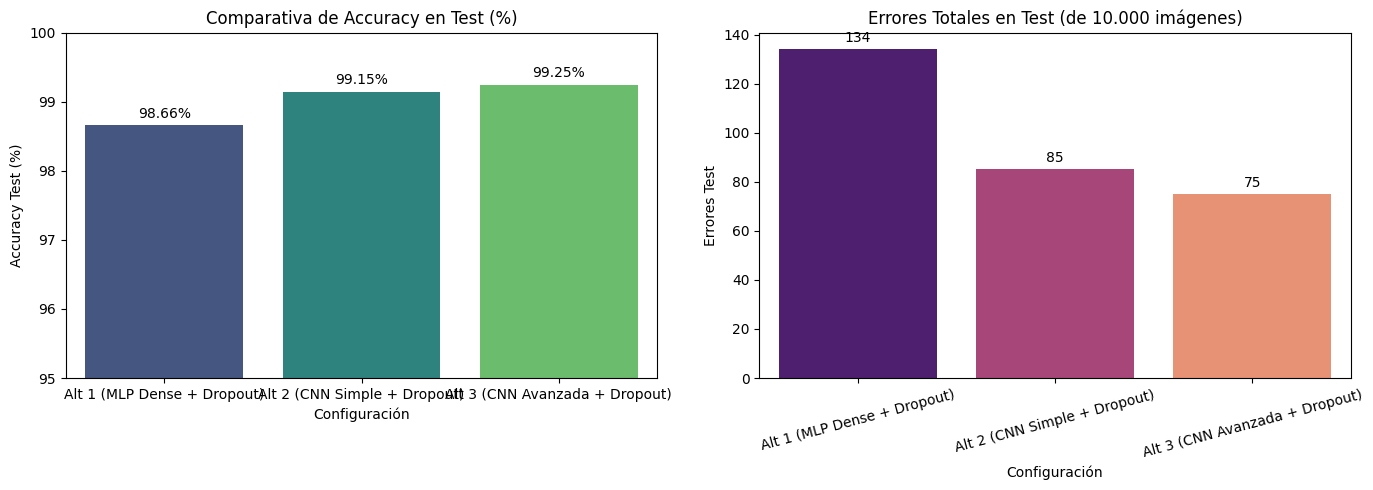


El modelo seleccionado como 'Mejor Configuración' es: Alt 3 (CNN Avanzada + Dropout)


In [5]:
display(df_resultados)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
sns.barplot(x='Configuración', y='Accuracy Test (%)', data=df_resultados, palette='viridis', ax=axes[0])
axes[0].set_title('Comparativa de Accuracy en Test (%)')
axes[0].set_ylim(95, 100)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2.0, p.get_height()), ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

# Errores
sns.barplot(x='Configuración', y='Errores Test', data=df_resultados, palette='magma', ax=axes[1])
axes[1].set_title('Errores Totales en Test (de 10.000 imágenes)')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2.0, p.get_height()), ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

idx_mejor = df_resultados['Accuracy Test (%)'].idxmax()
mejor_config_nombre = df_resultados.loc[idx_mejor, 'Configuración']
mejor_modelo = modelos_entrenados[mejor_config_nombre]

print(f"\nEl modelo seleccionado como 'Mejor Configuración' es: {mejor_config_nombre}")

#6.Matriz de Confusión y Guardado en Disco

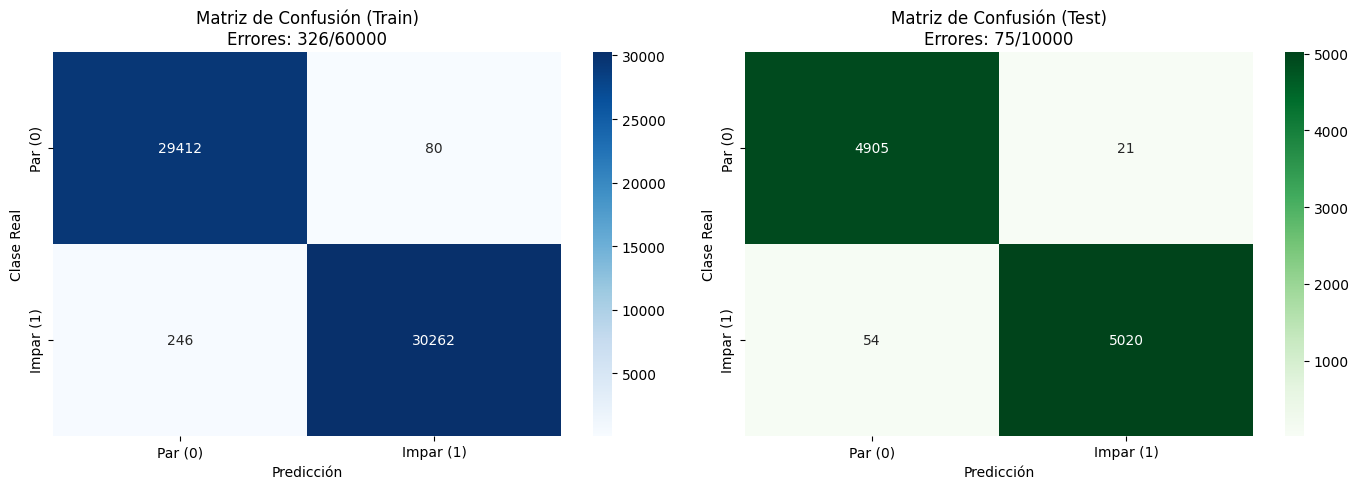


Reporte de Clasificación en Test:

              precision    recall  f1-score   support

     Par (0)       0.99      1.00      0.99      4926
   Impar (1)       1.00      0.99      0.99      5074

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

Modelo guardado correctamente como 'mejor_modelo_par_impar.keras'


In [6]:
# Predicciones del mejor modelo
y_pred_prob_train = mejor_modelo.predict(X_train, verbose=0)
y_pred_train = (y_pred_prob_train > 0.5).astype(int).reshape(-1)

y_pred_prob_test = mejor_modelo.predict(X_test, verbose=0)
y_pred_test = (y_pred_prob_test > 0.5).astype(int).reshape(-1)

cm_train = confusion_matrix(y_train, y_pred_train)
cm_test = confusion_matrix(y_test, y_pred_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'])
axes[0].set_title(f'Matriz de Confusión (Train)\nErrores: {np.sum(y_pred_train != y_train)}/60000')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Clase Real')

sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', ax=axes[1], xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'])
axes[1].set_title(f'Matriz de Confusión (Test)\nErrores: {np.sum(y_pred_test != y_test)}/10000')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Clase Real')

plt.tight_layout()
plt.show()

print("\nReporte de Clasificación en Test:\n")
print(classification_report(y_test, y_pred_test, target_names=['Par (0)', 'Impar (1)']))

# Guardar modelo en disco (.keras)
nombre_archivo = "mejor_modelo_par_impar.keras"
mejor_modelo.save(nombre_archivo)
print(f"Modelo guardado correctamente como '{nombre_archivo}'")

#7.Conclusión
¿Por qué la 'CNN Avanzada + Dropout' obtuvo el mejor resultado?

El modelo 3 logró la mayor precisión y el menor número de errores en el conjunto de test. Este rendimiento superior frente a las otras dos alternativas se debe a varios factores clave de su arquitectura:


### 1. Extracción jerárquica de características (2 bloques convolucionales vs 1 o ninguno)
* **Frente al MLP (`mlp_dense`):** El MLP aplana la imagen a un vector de 784 píxeles desde el inicio, perdiendo por completo la relación espacial entre píxeles vecinos (no sabe qué píxel está arriba, abajo o al lado de otro).
* **Frente a la CNN Simple (`cnn_simple`):** La CNN simple solo tiene 1 capa convolucional, por lo que solo aprende patrones visuales muy básicos (bordes o líneas simples).
* **La ventaja de la CNN Avanzada:** Al encadenar dos capas de convolución (`Conv2D` de 32 y 64 filtros), la red aprende de forma **jerárquica**:
  1. La **primera capa** detecta bordes y trazados elementales.
  2. La **segunda capa** combina esos bordes para identificar formas visuales complejas (bucles, curvas cerradas, cruces) fundamentales para diferenciar si un número es par o impar.



### 2. Invarianza a pequeñas variaciones (Doble `MaxPooling2D`)
Al aplicar dos capas de *Pooling*, la red reduce la dimensión espacial sucesivamente de $28 \times 28$ a $14 \times 14$ y finalmente a $7 \times 7$. Esto permite que el modelo sea capaz de reconocer las características del número sin importar si el trazo está ligeramente movido, inclinado o si cambia el grosor de la línea.



### 3. Control de sobreajuste mediante Dropout
Al ser la red más profunda de las tres, existía el riesgo de que memorizara los datos de entrenamiento (overfitting). Sin embargo, la inclusión de capas de Dropout más agresivas (0.4 y 0.3) en la parte densa obligó al modelo a no depender de neuronas específicas, logrando una excelente capacidad de generalización con datos nuevos (conjunto de test).


##Cierre


En defininitva, la CNN Avanzada combina lo mejor de ambos mundos: la capacidad de las redes convolucionales profundas para procesar imágenes en 2D sin perder información espacial, junto con una buena regulación mediante Dropout para no sobreajustarse. Por esta razón es la arquitectura óptima para este problema.